In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np

# 固定随机种子，让 DataLoader 的 shuffle、模型初始化都可复现
# 不固定的话，每次重跑训练曲线会略有差异，对比时容易混淆
torch.manual_seed(42)

# matplotlib 中文字体（按系统取一个能用的）
plt.rcParams['font.sans-serif'] = ['Heiti TC', 'PingFang SC', 'Songti SC', 'STHeiti', 'Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False

# 数据预处理: 转 tensor + 归一化
# - ToTensor: 把 PIL 图 (uint8, 0-255) 转成 float tensor, 范围 [0, 1], shape 由 (H, W, C) 变成 (C, H, W)
# - Normalize: 减均值除标准差, 让像素分布零均值、单位方差
#   0.1307 / 0.3081 是 MNIST 训练集像素的均值/标准差 (业界写死的常数)
#   为什么要这一步? 后面归一化那节会展开讲—简单说, 能让训练更稳、收敛更快
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,)),
])

# 第一次跑会自动从网上下载到 ./data/, 之后走本地缓存
train_set = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_set  = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform)

# DataLoader 把数据集切成 batch
# - 训练集 shuffle=True: 每个 epoch 打乱顺序, 避免模型记住数据出现的次序
# - 测试集 shuffle=False: 评估时顺序无所谓, 关掉 shuffle 让结果可复现
train_loader = DataLoader(train_set, batch_size=128, shuffle=True)
test_loader  = DataLoader(test_set,  batch_size=256, shuffle=False)

print(f'训练集: {len(train_set)} 张')
print(f'测试集: {len(test_set)} 张')
print(f'每张图: {train_set[0][0].shape} (通道 x 高 x 宽) ')

训练集: 60000 张
测试集: 10000 张
每张图: torch.Size([1, 28, 28]) (通道 x 高 x 宽) 


In [ ]:
# 取 9 张样本看一下
fig, axes = plt.subplots(3, 3, figsize=(6, 6))
for i, ax in enumerate(axes.flat):
    img, label = train_set[i]
    # img 已经归一化过, 反归一化回去显示 (不然颜色不对)
    ax.imshow(img.squeeze() * 0.3081 + 0.1307, cmap='gray')
    ax.set_title(f'label: {label}', fontsize=12)
    ax.axis('off')  
plt.suptitle('MNIST 训练集前 9 张', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

In [3]:
# ========================================================
# 手动初始化 4 个参数张量: W1, b1, W2, b2
# ========================================================
# 单独重跑这一段时，再固定一次种子，让权重初始化可复现
torch.manual_seed(42)

# requires_grad=True: 告诉 autograd" 这个张量是参数，需要记录梯度"
# 没有这个标记，loss.backward() 算不出 p.grad
#
# (2.0 / n_in) ** 0.5 是 He 初始化的标准差，专门给 ReLU 网络用
# 经验值，先留着；为什么是 sqrt(2/n_in)，参数初始化那节再讲
W1 = (torch.randn(784, 128) * (2.0 / 784) ** 0.5).requires_grad_()
b1 = torch.zeros(128, requires_grad=True)

# 第 2 层：128 -> 10 (输出 10 个类别的 logits)
W2 = (torch.randn(128, 10) * (2.0 / 128) ** 0.5).requires_grad_()
b2 = torch.zeros(10, requires_grad=True)

# 把 4 个参数放一个列表里, 后面统一更新
params = [W1, b1, W2, b2]
lr = 0.1  # 学习率: 每次梯度下降迈多大一步. 先拍0.1, 学习率与调度那节在细聊

print(f"网络共 {sum(p.numel() for p in params):,} 个参数")

网络共 101,770 个参数


In [4]:
# ========================================================
# 训练 5 个 epoch
# ========================================================
# 一个 epoch = 把整个训练集 (60000 张) 完整过一遍
# 一个 batch = 128 张 (DataLoader 切的), 所以一个 epoch 大约 469 个 batch
train_losses = []
test_accs = []

for epoch in range(5):
    running_loss = 0.0    # 累积本 epoch 所有 batch 的 loss × 样本数, 最后求平均
    n_samples = 0
    
    for xb, yb in train_loader:
        # xb 形状 (128, 1, 28, 28), yb 形状 (128,)
        # 我们的网络只识别 1D 向量, 所以把图像拍平成 (128, 784)
        x = xb.view(-1, 784)
        
        # —— ① forward: 「线性 + 非线性」的组合 ——
        h = F.relu(x @ W1 + b1)             # 隐藏层: 内层线性变换, 然后使用非线性函数 ReLU 激活
        logits = h @ W2 + b2                # 输出层: 只做线性变换, 不加softmax
                                            # (CrossEntropy 内部会做 log_softmax, 自己加反而数值不稳)

        # —— ② loss: 算预测和真值的差距 ——
        # cross_entropy 接收 logits (未归一化的分数) 和整数标签, 自动做 softmax + 交叉熵
        loss = F.cross_entropy(logits, yb)
        
        # —— ③ backward: 反向传播 ——
        # autograd 顺着前向那张计算图, 从 loss 一路链式求导回每个 requires_grad 的张量
        # 求出来的梯度自动累加到 p.grad (所以下面要记得清零)
        loss.backward()
        
        # —— ④ step: 梯度下降, 沿梯度反方向更新参数 ——
        # 参数更新本身不需要建图 (不需要对"更新这一步"再求导), 所以包在 no_grad 里
        with torch.no_grad():
            for p in params:
                p -= lr * p.grad        # 沿梯度反方向迈 lr 这么大一步
                p.grad.zero_()          # 清零, 防止下个 batch 的梯度叠加进来
        
        running_loss += loss.item() * yb.size(0)
        n_samples += yb.size(0)

    train_loss = running_loss / n_samples    # 整个 epoch 的平均 loss
    
    # —— 评估: 测试集上跑一遍前向, 统计准确率 (不算梯度, 更快更省内存) ——
    correct = 0
    with torch.no_grad():
        for xb, yb in test_loader:
            x = xb.view(-1, 784)
            logits = F.relu(x @ W1 + b1) @ W2 + b2
            correct += (logits.argmax(1) == yb).sum().item()
    test_acc = correct / len(test_set)
    
    train_losses.append(train_loss)
    test_accs.append(test_acc)
    print(f'epoch {epoch+1}/5  train_loss={train_loss:.4f}  test_acc={test_acc:.4f}')

epoch 1/5  train_loss=0.2839  test_acc=0.9488
epoch 2/5  train_loss=0.1387  test_acc=0.9651
epoch 3/5  train_loss=0.1011  test_acc=0.9674
epoch 4/5  train_loss=0.0806  test_acc=0.9714
epoch 5/5  train_loss=0.0670  test_acc=0.9742


findfont: Generic family 'sans-serif' not found because none of the following families were found: Heiti TC, PingFang SC, Songti SC, STHeiti, Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the following families were found: Heiti TC, PingFang SC, Songti SC, STHeiti, Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the following families were found: Heiti TC, PingFang SC, Songti SC, STHeiti, Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the following families were found: Heiti TC, PingFang SC, Songti SC, STHeiti, Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the following families were found: Heiti TC, PingFang SC, Songti SC, STHeiti, Arial Unicode MS
findfont: Generic family 'sans-serif' not found because none of the following families were found: Heiti TC, PingFang SC, Songti SC, STHeiti, Arial Unicode MS
findfont: Generic family 'sans-serif' not foun

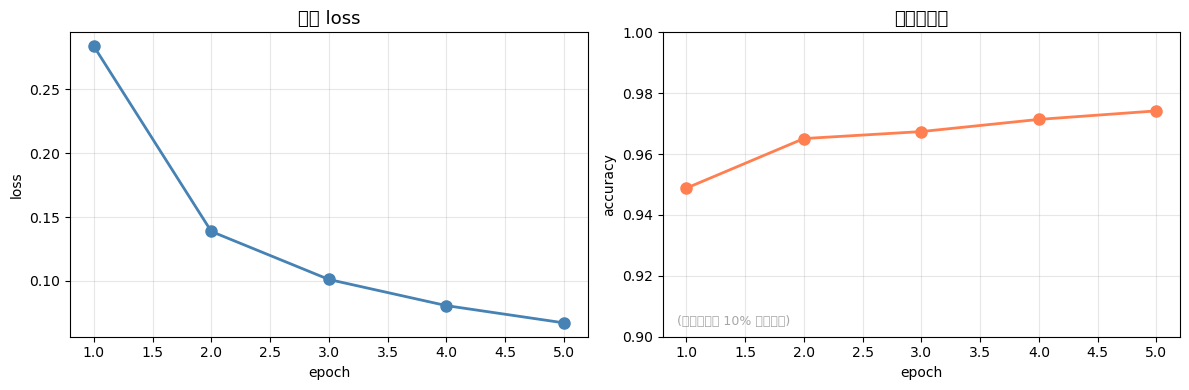

In [5]:
# ================= 可视化绘图（基于你提供的第一张图补全） =================

# 1. 创建画布（补充了原图中未显示的 fig 和 axes 定义）
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

epochs = range(1, len(train_losses) + 1)

# 左: 训练 loss—应该单调下降
axes[0].plot(epochs, train_losses, '-o', color='steelblue', lw=2, markersize=8)
axes[0].set_title('训练 loss', fontsize=13)
axes[0].set_xlabel('epoch')
axes[0].set_ylabel('loss')
axes[0].grid(alpha=0.3)

# 右: 测试准确率—应该单调上升
# 实际值都在 0.94 以上，把 y 轴从 0.9 起画曲线变化更清楚
# (随机猜的基线是 0.10，远远低于此图范围，用文字标注一下即可)
axes[1].plot(epochs, test_accs, '-o', color='coral', lw=2, markersize=8)
axes[1].set_title('测试准确率', fontsize=13)
axes[1].set_xlabel('epoch')
axes[1].set_ylabel('accuracy')
axes[1].set_ylim(0.9, 1.0) # 限制 y 轴范围，放大差异
axes[1].annotate(' (随机猜基线 10% 远在图外) ', xy=(0.02, 0.04),
                 xycoords='axes fraction', fontsize=9, color='gray', alpha=0.7)
axes[1].grid(alpha=0.3)

# 调整布局并显示
plt.tight_layout()
plt.show()